# Exercise 1 (10 points)

In this exercise, we will practice how to test a function in Python. Imagine you have a function `normalize_data()` that takes in a `pandas` DataFrame and normalizes each column (scales the data so that the values in each column are between 0 and 1). You want to test this function to ensure it works correctly.


```
import pandas as pd

def normalize_data(df):
    return (df - df.min()) / (df.max() - df.min())
```

Write a test function using `assert` statements to verify that:

- Each column's minimum value is 0 and maximum value is 1 after normalization.
- The function raises an error if the input is not a DataFrame.
- The function does not alter the original DataFrame.



In [1]:
import pandas as pd

def normalize_data(df):
    if not isinstance(df, pd.DataFrame):
        raise ValueError("Input must be a pandas DataFrame")
    return (df - df.min()) / (df.max() - df.min())

# Test function
def test_normalize_data():
    # Create a sample DataFrame
    df = pd.DataFrame({
        'A': [10, 20, 30],
        'B': [40, 50, 60],
        'C': [70, 80, 90]
    })

    # Copy the original DataFrame for comparison
    original_df = df.copy()

    # Test 1: Each column should be normalized between 0 and 1
    assert (normalize_data(df).min().min() == 0), "Minimum value should be 0"
    assert (normalize_data(df).max().max() == 1), "Maximum value should be 1"

    # Test 2: Function should raise an error if input is not a DataFrame
    try:
        normalize_data([1, 2, 3])
    except ValueError as e:
        assert str(e) == "Input must be a pandas DataFrame"

    # Test 3: Original DataFrame should not be modified
    assert df.equals(original_df), "Original DataFrame should not be modified"

    print("All tests passed.")

# Run the test function
test_normalize_data()

All tests passed.


# Exercise 2

In this exercise, we will practice data visualiation with the `credit_card_transactions_India.csv` data file. This dataset contains insights into a collection of credit card transactions made in India, offering a comprehensive look at the spending habits of Indians across the nation. From the Gender and Card type used to carry out each transaction, to which city saw the highest amount of spending and even what kind of expenses were made, this dataset paints an overall picture about how money is being spent in India today. A brief description of the features is shown below.

- `City`: The city in which the transaction took place. 
- `Date`: The date of the transaction. 
- `Card Type`: The type of credit card used for the transaction.
- `Exp Type`: The type of expense associated with the transaction. 
- `Gender`: The gender of the cardholder. 
- `Amount`: The amount of the transaction.

### Exercise 2(a) (2 points)

Load `pandas`, `matplotlib`, and `seaborn`.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Exercise 2(b) (2 points)

Read the `credit_card_transactions_India.csv` data file and create a data frame called `credit`.

In [3]:
credit = pd.read_csv("credit_card_transactions_India.csv")
credit.head()

,index,City,Date,Card Type,Exp Type,Gender,Amount
0,0,"Delhi, India",29-Oct-14,Gold,Bills,F,82475
1,1,"Greater Mumbai, India",22-Aug-14,Platinum,Bills,F,32555
2,2,"Bengaluru, India",27-Aug-14,Silver,Bills,F,101738
3,3,"Greater Mumbai, India",12-Apr-14,Signature,Bills,F,123424
4,4,"Bengaluru, India",5-May-15,Gold,Bills,F,171574


### Exercise 2(c) (3 points)

Convert `Date` to `date-time` format.

In [4]:
credit["Date"] = pd.to_datetime(credit["Date"], format='%d-%b-%y')

### Exercise 2(d) (3 points)

Select credit card transaction in `Delhi, India` and create a data frame called `Delhi`.

In [5]:
Delhi = credit[credit["City"] == "Delhi, India"].reset_index(drop=True)
Delhi.head()

,index,City,Date,Card Type,Exp Type,Gender,Amount
0,0,"Delhi, India",2014-10-29,Gold,Bills,F,82475
1,5,"Delhi, India",2014-09-08,Silver,Bills,F,100036
2,6,"Delhi, India",2015-02-24,Gold,Bills,F,143250
3,8,"Delhi, India",2014-03-28,Silver,Bills,F,192247
4,9,"Delhi, India",2014-09-01,Platinum,Bills,F,67932


### Exercise 2(e) (3 points)

Create a frequency table of `Card Type` of the `Delhi` data frame.

In [6]:
Delhi["Card Type"].value_counts(normalize=True)

Card Type
Silver       0.274555
Signature    0.250431
Gold         0.247846
Platinum     0.227168
Name: proportion, dtype: float64

### Exercise 2(e) (6 points)

Create a time-series plot of `Amount` based on the different `Card Type`.

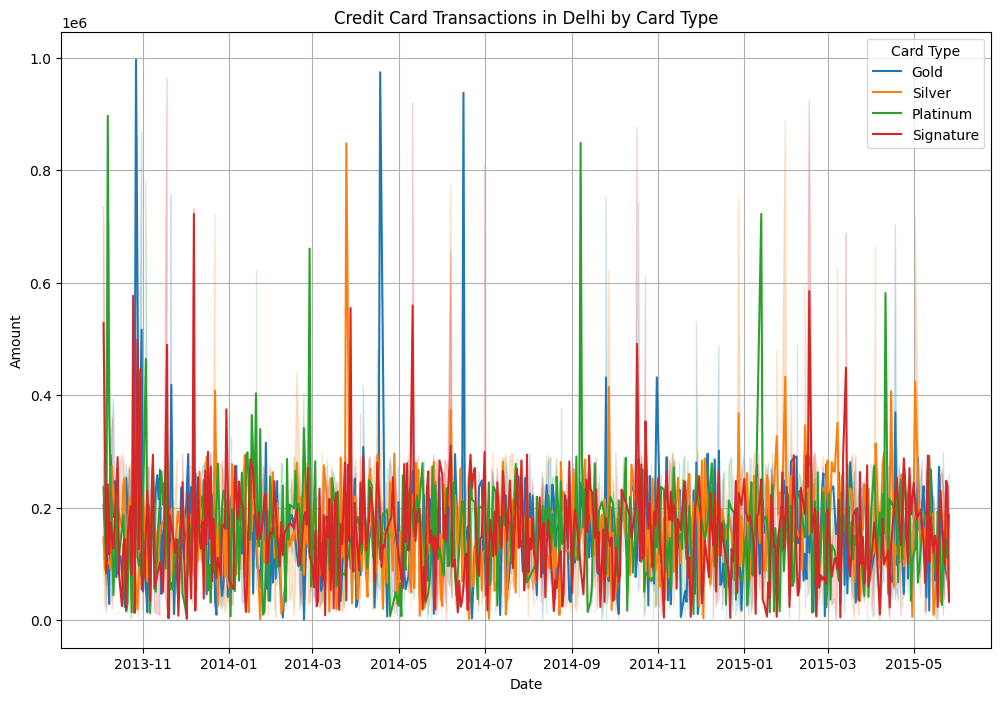

In [9]:
fig, ax = plt.subplots(figsize=(12, 8))

sns.lineplot(data=Delhi, x="Date", y="Amount", ax=ax, hue="Card Type")
ax.set_title("Credit Card Transactions in Delhi by Card Type")
ax.set_xlabel("Date")
ax.set_ylabel("Amount")
ax.grid()
plt.show()

### Exercise 2(f) (6 points)

Create a time-series plot of `Amount` based on `Gender`.

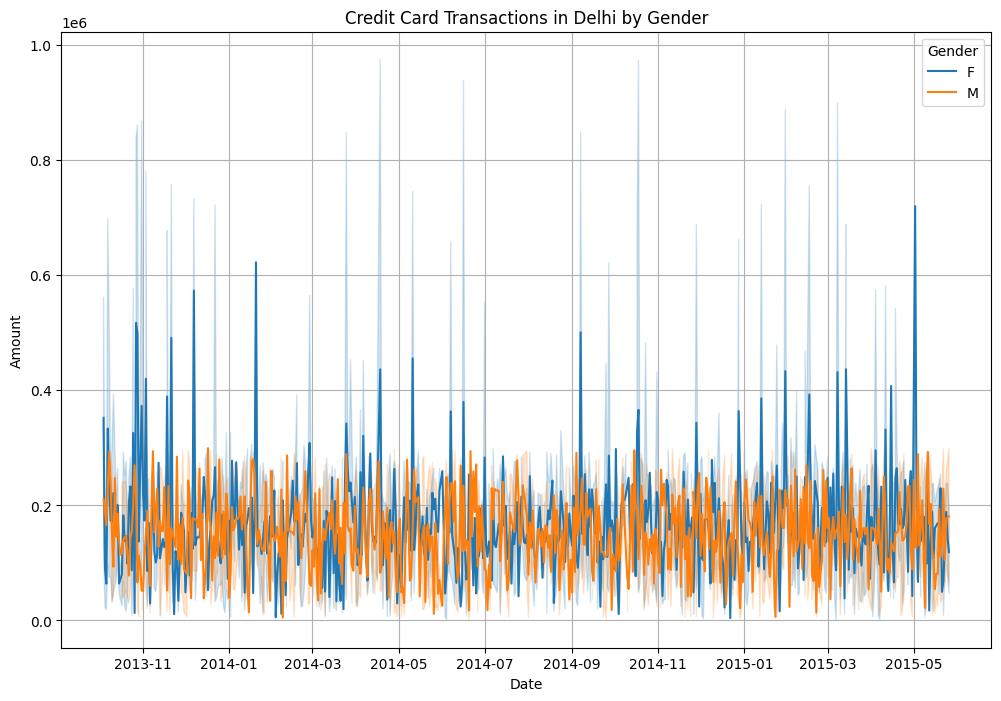

In [10]:
fig, ax = plt.subplots(figsize=(12, 8))

sns.lineplot(data=Delhi, x="Date", y="Amount", ax=ax, hue="Gender")
ax.set_title("Credit Card Transactions in Delhi by Gender")
ax.set_xlabel("Date")
ax.set_ylabel("Amount")
ax.grid()
plt.show()

# Exercise 3 (10 points)

Conceptual question on testing code in applied data science.

A teammate tells you: *"My data-cleaning and modeling pipeline runs without errors and the model's accuracy is 95%, so the code must be correct and I don't need to write tests."*

Do you agree? In your answer:

1. Explain why a pipeline that runs without errors and reports a high accuracy does not guarantee that the code is correct. Give at least two examples of silent bugs that could occur in a data science project (e.g., data leakage, incorrect joins, mishandled missing values).
2. Explain why testing data science code is harder than testing traditional software, and name two practices that help (e.g., fixing random seeds, using small hand-made fixtures, testing properties/invariants rather than exact values).

I do not agree.

1. Running without errors and high accuracy do not imply correctness. Most bugs in applied data science/machine learning are silent; that is, they do not raise exceptions, they just produce wrong numbers. Reasons for this:
   - Data leakage
   - Mishandled missing values
   - Class imbalance

2. Data science/machine learning code is harder to test because:
   - Outputs are often stochastic
   - There is often no single correct answer to compare against
   - Behavior depends on the data, which could change over time